# Laboratorium 1: obraz jako dane, pierwszy klasyfikator obrazów (MLP)


## 1. Cel ćwiczenia

Celem było wytrenowanie sieci MLP, która rozpoznaje rodzaj ubrania na obrazku, sprawdzenie jak liczba i wielkość warstw ukrytych wpływa na wynik i zobaczenie, gdzie model się myli

Dodatkowo sprawdziłem macierz pomyłek oraz wpływ liczby epok i learning rate

Wybrałem zbiór FashionMNIST

MLP spłaszcza obraz do jednego wektora i nie wie, które piksele są obok siebie, więc dobrze działa tylko wtedy, gdy obiekty są zawsze w podobnym miejscu i mają podobną wielkość

W FashionMNIST ubrania są wyśrodkowane, leżą na czarnym tle i mają podobny rozmiar, więc MLP daje tu sensowny wynik i dobrze widać różnice między wariantami

Na CIFAR-10 są kolorowe zdjęcia z różnym tłem i obiektami w różnych miejscach, MLP osiąga tam zwykle tylko około 50-55%, więc porównanie architektur niewiele by pokazało

FashionMNIST ma też mniejsze obrazki (784 wartości zamiast 3072), więc trening jest szybszy i mogłem każdy wariant puścić 3 razy

Zbiór pochodzi z katalogu Zalando, więc to realny problem: automatyczne przypisywanie zdjęć produktów do kategorii


## 2. Metoda i implementacja

Użyłem PyTorch, torchvision, scikit-learn (macierz pomyłek), pandas i matplotlib, trening szedł na CPU

Z 60 000 obrazów treningowych wydzieliłem losowo 6 000 do walidacji, czyli do treningu zostało 54 000, a 10 000 testowych używam tylko do podania wyniku

Najlepszą architekturę wybierałem po wyniku na walidacji, a nie na teście, żeby wynik testowy był uczciwą oceną modelu

Piksele są przeskalowane do zakresu 0-1 i standaryzowane tak samo jak w ćwiczeniu (mean 0,2860, std 0,3530)

Klasę MLP z ćwiczenia przerobiłem tak, żeby liczbę i rozmiar warstw ukrytych podawać jako krotkę, np. (512, 256)

Ustawienia dla wszystkich wariantów: Adam z lr 0,001, batch 128, funkcja straty CrossEntropyLoss, 15 epok, bez regularyzacji i augmentacji

Sprawdziłem 5 architektur: model bazowy z ćwiczenia (256, 128) i 4 warianty: (128), (512, 256), (512, 256, 128) i (1024, 512, 256)

Każdą architekturę trenowałem 3 razy z innym ziarnem losowości (0, 1, 2) i podaję średnią i odchylenie standardowe, bo pojedynczy trening zależy od losowych wag na starcie i różnice między wariantami mogłyby wyjść przypadkiem


# Importy i wybór urządzenia

In [ ]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader, TensorDataset

device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("figures", exist_ok=True)
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cu130 | urządzenie: cpu


Wczytanie FashionMNIST, standaryzacja i podział na trening, walidację i test

Dane wczytuję raz do tensora zamiast robić ToTensor i Normalize dla każdego obrazka osobno, wynik jest ten sam, a trening szybszy

In [ ]:
MEAN, STD = 0.2860, 0.3530


def to_tensors(ds):
    x = ds.data.float().div(255).sub(MEAN).div(STD).unsqueeze(1)
    return x, ds.targets.clone()


train_raw = torchvision.datasets.FashionMNIST("./data", train=True, download=True)
test_raw = torchvision.datasets.FashionMNIST("./data", train=False, download=True)
classes = train_raw.classes

x_full, y_full = to_tensors(train_raw)
x_test, y_test = to_tensors(test_raw)

perm = torch.randperm(len(x_full), generator=torch.Generator().manual_seed(42))
val_idx, train_idx = perm[:6000], perm[6000:]
x_train, y_train = x_full[train_idx], y_full[train_idx]
x_val, y_val = x_full[val_idx], y_full[val_idx]

train_ds = TensorDataset(x_train, y_train)
val_dl = DataLoader(TensorDataset(x_val, y_val), batch_size=256)
test_dl = DataLoader(TensorDataset(x_test, y_test), batch_size=256)

print("Klasy:", classes)
print("Trening:", len(x_train), "| walidacja:", len(x_val), "| test:", len(x_test))
print("Kształt obrazu:", tuple(x_train[0].shape),
      "| średnia/odch. std po standaryzacji:", round(x_train.mean().item(), 3), round(x_train.std().item(), 3))

Klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Trening: 54000 | walidacja: 6000 | test: 10000
Kształt obrazu: (1, 28, 28) | średnia/odch. std po standaryzacji: -0.0 1.0


Model MLP z dowolną liczbą warstw ukrytych, na wyjściu 10 logitów bez softmax, bo softmax robi już CrossEntropyLoss

Pod spodem liczba parametrów każdej architektury

In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim=28 * 28, hidden=(256, 128), n_classes=10):
        super().__init__()
        layers = [nn.Flatten()]
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


for h in [(128,), (256, 128), (512, 256), (512, 256, 128), (1024, 512, 256)]:
    n = count_params(MLP(hidden=h))
    print(f"{str(h):18s} parametry: " + f"{n:>9_}".replace("_", " "))

(128,)             parametry:   101 770
(256, 128)         parametry:   235 146
(512, 256)         parametry:   535 818
(512, 256, 128)    parametry:   567 434
(1024, 512, 256)   parametry: 1 462 538


Funkcje do treningu i oceny, pętla jak w ćwiczeniu: forward, strata, backward, krok Adama

Po każdej epoce zapisuję stratę treningową oraz stratę i accuracy na walidacji i teście

In [ ]:
def evaluate(model, dl):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum / total, correct / total


def fit(hidden, seed=0, epochs=15, lr=1e-3, batch_size=128, verbose=False):
    torch.manual_seed(seed)
    model = MLP(hidden=hidden).to(device)
    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                          generator=torch.Generator().manual_seed(seed))
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "val_loss", "val_acc", "test_loss", "test_acc"]}

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * yb.numel()
        val_loss, val_acc = evaluate(model, val_dl)
        test_loss, test_acc = evaluate(model, test_dl)
        for k, v in zip(hist, [run_loss / len(train_ds), val_loss, val_acc, test_loss, test_acc]):
            hist[k].append(v)
        if verbose:
            print(f"Epoka {epoch:2d} | strata trening {hist['train_loss'][-1]:.3f} | walid. {val_loss:.3f} "
                  f"| test {test_loss:.3f} | acc walid. {val_acc * 100:.2f}% | acc test {test_acc * 100:.2f}%")
    return model, hist

## 3. Wyniki

Model bazowy z ćwiczenia (784-256-128-10), trenowany 15 epok zamiast 8, wynik po 8 epokach też wypisuję

In [ ]:
t0 = time.time()
base_model, base_hist = fit((256, 128), seed=0, verbose=True)
print(f"\nAccuracy testowe po 8 epokach:  {base_hist['test_acc'][7] * 100:.2f}%")
print(f"Accuracy testowe po 15 epokach: {base_hist['test_acc'][-1] * 100:.2f}%")
print(f"Czas: {time.time() - t0:.0f} s")

Epoka  1 | strata trening 0.495 | walid. 0.447 | test 0.461 | acc walid. 82.38% | acc test 82.90%


Epoka  2 | strata trening 0.351 | walid. 0.349 | test 0.368 | acc walid. 86.88% | acc test 86.61%


Epoka  3 | strata trening 0.315 | walid. 0.334 | test 0.346 | acc walid. 87.52% | acc test 86.99%


Epoka  4 | strata trening 0.290 | walid. 0.338 | test 0.356 | acc walid. 87.65% | acc test 87.01%


Epoka  5 | strata trening 0.270 | walid. 0.322 | test 0.343 | acc walid. 88.42% | acc test 87.53%


Epoka  6 | strata trening 0.257 | walid. 0.311 | test 0.335 | acc walid. 88.87% | acc test 87.88%


... (5 outputs left out)

Epoka 12 | strata trening 0.183 | walid. 0.319 | test 0.337 | acc walid. 89.42% | acc test 88.87%


Epoka 13 | strata trening 0.174 | walid. 0.337 | test 0.357 | acc walid. 89.05% | acc test 88.57%


Epoka 14 | strata trening 0.165 | walid. 0.335 | test 0.354 | acc walid. 89.37% | acc test 88.77%


Epoka 15 | strata trening 0.159 | walid. 0.334 | test 0.360 | acc walid. 89.52% | acc test 89.15%

Accuracy testowe po 8 epokach:  87.94%
Accuracy testowe po 15 epokach: 89.15%
Czas: 22 s


Model bazowy ma 235 146 parametrów i po 8 epokach dał 87,94% accuracy na teście, a po 15 epokach 89,15%

W notatniku z zajęć było 88,69% po 8 epokach, u mnie wyszło trochę mniej, bo trenowałem na 54 000 obrazkach zamiast 60 000 (reszta poszła na walidację), a do tego trening jest losowy

Porównanie architektur, każda trenowana 3 razy po 15 epok

In [ ]:
ARCHS = [(128,), (256, 128), (512, 256), (512, 256, 128), (1024, 512, 256)]
SEEDS = [0, 1, 2]
EPOCHS = 15

runs = {}
models = {}
t0 = time.time()
for h in ARCHS:
    for s in SEEDS:
        if h == (256, 128) and s == 0:
            model, hist = base_model, base_hist
        else:
            model, hist = fit(h, seed=s, epochs=EPOCHS)
        runs[(h, s)] = hist
        if s == 0:
            models[h] = model
    accs = [runs[(h, s)]["test_acc"][-1] * 100 for s in SEEDS]
    print(f"{str(h):18s} test acc: {np.mean(accs):.2f}% ± {np.std(accs):.2f}  ({time.time() - t0:.0f} s)")

(128,)             test acc: 88.09% ± 0.13  (40 s)


(256, 128)         test acc: 88.58% ± 0.46  (82 s)


(512, 256)         test acc: 88.74% ± 0.27  (195 s)


(512, 256, 128)    test acc: 88.78% ± 0.34  (315 s)


(1024, 512, 256)   test acc: 88.67% ± 0.09  (616 s)


In [ ]:
rows = []
for h in ARCHS:
    val = [runs[(h, s)]["val_acc"][-1] * 100 for s in SEEDS]
    test = [runs[(h, s)]["test_acc"][-1] * 100 for s in SEEDS]
    tr_loss = [runs[(h, s)]["train_loss"][-1] for s in SEEDS]
    te_loss = [runs[(h, s)]["test_loss"][-1] for s in SEEDS]
    rows.append({
        "architektura": "784-" + "-".join(map(str, h)) + "-10",
        "warstwy ukryte": len(h),
        "parametry": count_params(MLP(hidden=h)),
        "acc walid. [%]": f"{np.mean(val):.2f} ± {np.std(val):.2f}",
        "acc test [%]": f"{np.mean(test):.2f} ± {np.std(test):.2f}",
        "strata trening": round(float(np.mean(tr_loss)), 3),
        "strata test": round(float(np.mean(te_loss)), 3),
        "_val_mean": np.mean(val),
    })
results = pd.DataFrame(rows)
best_arch = ARCHS[int(results["_val_mean"].idxmax())]
results = results.drop(columns="_val_mean")
print("Najlepsza architektura (walidacja):", best_arch)
results

Najlepsza architektura (walidacja): (512, 256)


,architektura,warstwy ukryte,parametry,acc walid. [%],acc test [%],strata trening,strata test
0,784-128-10,1,101770,88.77 ± 0.20,88.09 ± 0.13,0.187,0.359
1,784-256-128-10,2,235146,89.12 ± 0.29,88.58 ± 0.46,0.158,0.378
2,784-512-256-10,2,535818,89.29 ± 0.29,88.74 ± 0.27,0.141,0.405
3,784-512-256-128-10,3,567434,89.07 ± 0.54,88.78 ± 0.34,0.150,0.395
4,784-1024-512-256-10,3,1462538,89.20 ± 0.10,88.67 ± 0.09,0.142,0.416


W tabeli są średnie ± odchylenie standardowe z 3 uruchomień po 15 epokach

Najlepszy wynik na walidacji miał wariant (512, 256): 89,29% na walidacji i 88,74% na teście, czyli tylko o 0,16 punktu procentowego więcej niż model bazowy

Najsłabszy był najmniejszy model z jedną warstwą (128): 88,09% na teście

Pozostałe 4 warianty różnią się na teście najwyżej o 0,2 punktu procentowego

Im większa sieć, tym niższa strata treningowa i wyższa testowa (0,359 dla najmniejszej i 0,416 dla największej)

Krzywe uczenia dla najlepszego wariantu (512, 256)

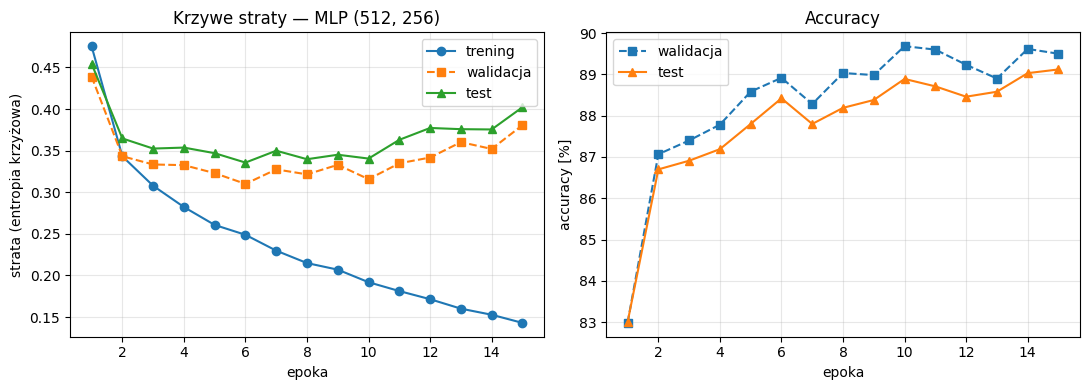

Najniższa strata testowa w epoce: 6
Różnica strata test - trening: epoka 1: -0.021, epoka 15: 0.259


In [ ]:
bh = runs[(best_arch, 0)]
ep = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ep, bh["train_loss"], "o-", label="trening")
ax1.plot(ep, bh["val_loss"], "s--", label="walidacja")
ax1.plot(ep, bh["test_loss"], "^-", label="test")
ax1.set(xlabel="epoka", ylabel="strata (entropia krzyżowa)", title=f"Krzywe straty — MLP {best_arch}")
ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(ep, [a * 100 for a in bh["val_acc"]], "s--", label="walidacja")
ax2.plot(ep, [a * 100 for a in bh["test_acc"]], "^-", label="test")
ax2.set(xlabel="epoka", ylabel="accuracy [%]", title="Accuracy")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/krzywe_uczenia.png", dpi=120); plt.show()

gap = [te - tr for tr, te in zip(bh["train_loss"], bh["test_loss"])]
print("Najniższa strata testowa w epoce:", int(np.argmin(bh["test_loss"])) + 1)
print(f"Różnica strata test - trening: epoka 1: {gap[0]:.3f}, epoka {EPOCHS}: {gap[-1]:.3f}")

Strata treningowa spada przez cały czas, z 0,476 do 0,143

Strata testowa jest najniższa w 6 epoce (0,336), a potem rośnie do 0,402 w 15 epoce

Różnica między stratą testową a treningową rośnie z prawie zera na początku do 0,259 na końcu, czyli model zaczyna się przeuczać

Accuracy mimo tego dalej powoli rośnie, na teście z 88,42% w 6 epoce do 89,12% w 15

Przykładowe predykcje najlepszego modelu, na zielono trafne, na czerwono błędne, w nawiasie pewność modelu (softmax)

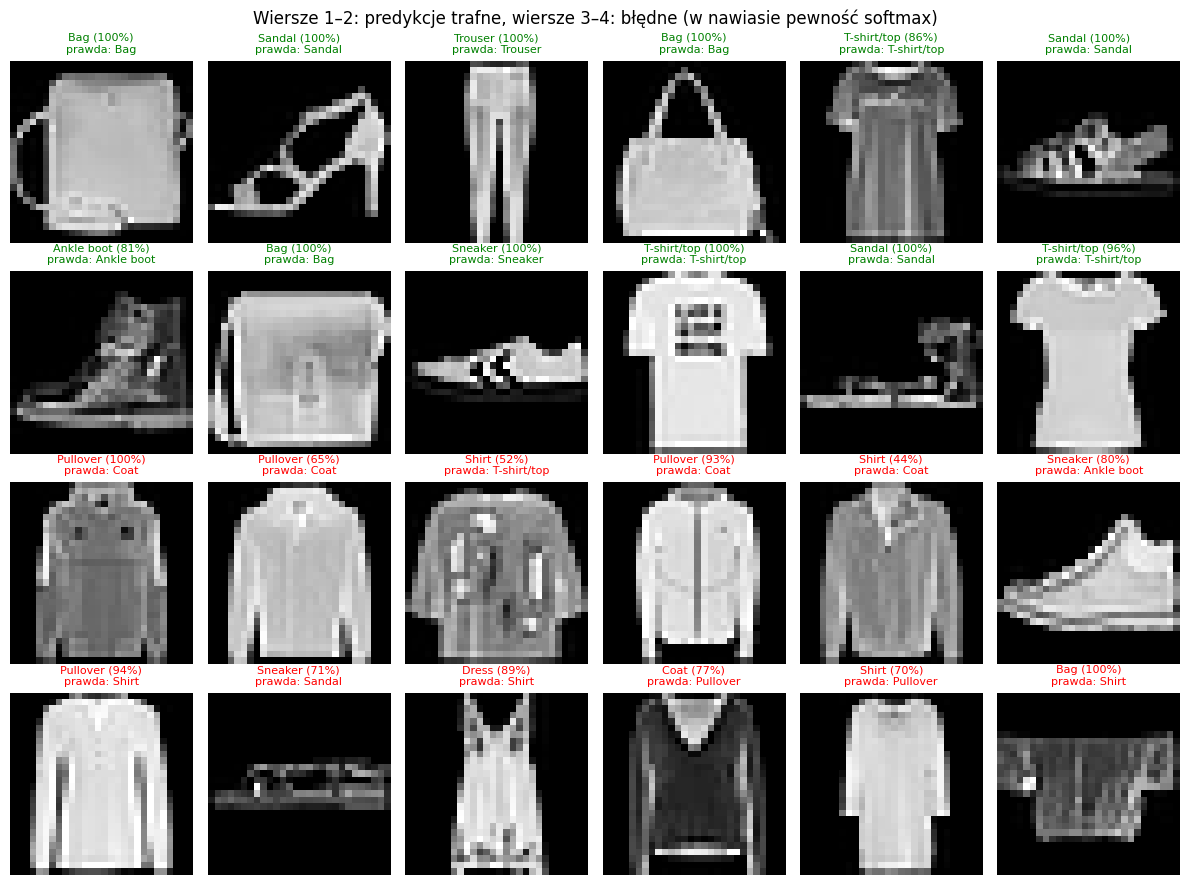

Błędne predykcje: 1088 z 10000
Średnia pewność softmax: trafne 95.8%, błędne 76.4%


In [ ]:
best_model = models[best_arch].eval()
with torch.no_grad():
    logits = torch.cat([best_model(xb.to(device)).cpu() for xb, _ in test_dl])
pred = logits.argmax(1)
conf = logits.softmax(1).max(1).values
ok = pred == y_test

g = torch.Generator().manual_seed(7)
ok_idx = torch.where(ok)[0]
bad_idx = torch.where(~ok)[0]
show = torch.cat([ok_idx[torch.randperm(len(ok_idx), generator=g)[:12]],
                  bad_idx[torch.randperm(len(bad_idx), generator=g)[:12]]])

fig, axes = plt.subplots(4, 6, figsize=(12, 9))
for ax, i in zip(axes.flat, show.tolist()):
    ax.imshow(x_test[i].squeeze() * STD + MEAN, cmap="gray")
    good = bool(ok[i])
    ax.set_title(f"{classes[pred[i]]} ({conf[i] * 100:.0f}%)\nprawda: {classes[y_test[i]]}",
                 fontsize=8, color="green" if good else "red")
    ax.axis("off")
fig.suptitle("Wiersze 1–2: predykcje trafne, wiersze 3–4: błędne (w nawiasie pewność softmax)")
plt.tight_layout(); plt.savefig("figures/predykcje.png", dpi=120); plt.show()

print(f"Błędne predykcje: {int((~ok).sum())} z {len(y_test)}")
print(f"Średnia pewność softmax: trafne {conf[ok].mean() * 100:.1f}%, błędne {conf[~ok].mean() * 100:.1f}%")

Model pomylił się na 1088 z 10 000 obrazków testowych, czyli accuracy wyszło 89,12%

Przy trafnych predykcjach średnia pewność to 95,8%, a przy błędnych 76,4%

Niektóre błędy model robi z pewnością prawie 100%, np. płaszcz uznał za sweter, a koszulę za torbę

Myli się głównie przy ubraniach na górę: koszulki, koszule, swetry i płaszcze mylą się ze sobą

Macierz pomyłek i accuracy dla każdej klasy (zakres dodatkowy)

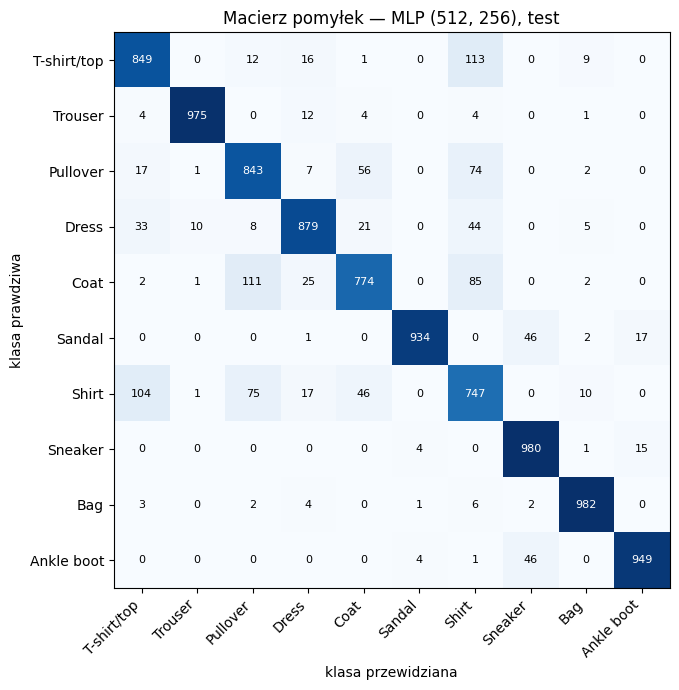

      klasa  accuracy [%]
      Shirt          74.7
       Coat          77.4
   Pullover          84.3
T-shirt/top          84.9
      Dress          87.9
     Sandal          93.4
 Ankle boot          94.9
    Trouser          97.5
    Sneaker          98.0
        Bag          98.2

Najczęściej mylone pary (suma w obie strony):
  T-shirt/top <-> Shirt: 217  (T-shirt/top->Shirt: 113, Shirt->T-shirt/top: 104)
  Pullover <-> Coat: 167  (Pullover->Coat: 56, Coat->Pullover: 111)
  Pullover <-> Shirt: 149  (Pullover->Shirt: 74, Shirt->Pullover: 75)
  Coat <-> Shirt: 131  (Coat->Shirt: 85, Shirt->Coat: 46)
  Sneaker <-> Ankle boot: 61  (Sneaker->Ankle boot: 15, Ankle boot->Sneaker: 46)


In [ ]:
cm = confusion_matrix(y_test.numpy(), pred.numpy())

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(10), classes, rotation=45, ha="right")
ax.set_yticks(range(10), classes)
ax.set(xlabel="klasa przewidziana", ylabel="klasa prawdziwa", title=f"Macierz pomyłek — MLP {best_arch}, test")
plt.tight_layout(); plt.savefig("figures/macierz_pomylek.png", dpi=120); plt.show()

per_class = pd.DataFrame({"klasa": classes, "accuracy [%]": (cm.diagonal() / cm.sum(1) * 100).round(1)})
print(per_class.sort_values("accuracy [%]").to_string(index=False))

off = cm.copy()
np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j] + off[j, i], classes[i], classes[j], off[i, j], off[j, i])
                for i in range(10) for j in range(i + 1, 10)), reverse=True)
print("\nNajczęściej mylone pary (suma w obie strony):")
for tot, a, b, ab, ba in pairs[:5]:
    print(f"  {a} <-> {b}: {tot}  ({a}->{b}: {ab}, {b}->{a}: {ba})")

Najgorzej rozpoznawana jest koszula (Shirt, 74,7%), potem płaszcz (Coat, 77,4%), sweter (Pullover, 84,3%) i koszulka (T-shirt/top, 84,9%)

Najlepiej rozpoznawane są torby (98,2%), buty sportowe (98,0%) i spodnie (97,5%)

Najtrudniejsza para klas to T-shirt/top i Shirt, w sumie 217 pomyłek (113 w jedną stronę i 104 w drugą)

Dalej są Pullover i Coat (167), Pullover i Shirt (149) oraz Coat i Shirt (131)

Buty mylą się tylko między sobą, np. Sneaker i Ankle boot (61 pomyłek), a z ubraniami prawie wcale

Wpływ liczby epok i learning rate dla najlepszej architektury (zakres dodatkowy): trening przez 40 epok z lr 0,001 i porównanie lr 0,0001, 0,001 i 0,01 przy 15 epokach

Czas: 195 s


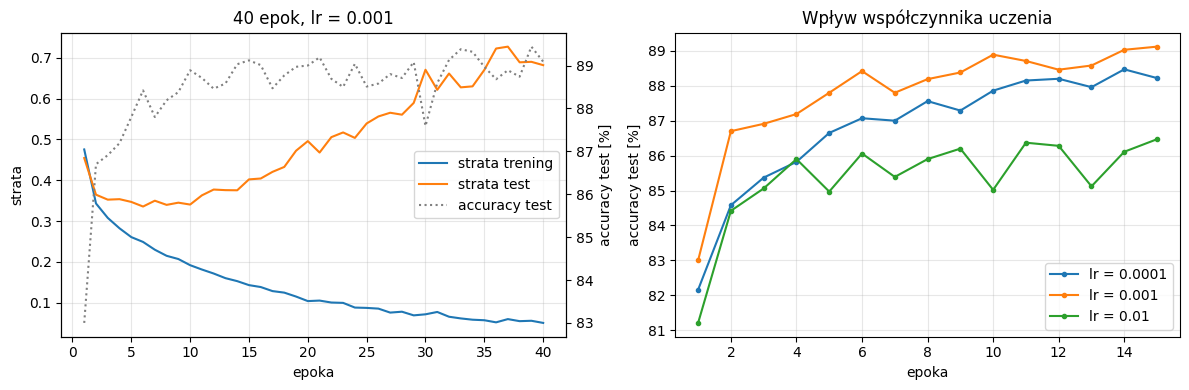

40 epok: min. strata test w epoce 6 (0.336), w epoce 40: 0.682; strata trening w epoce 40: 0.050
40 epok: acc test w epoce 15: 89.12%, maks.: 89.44% (epoka 39), w epoce 40: 89.09%
lr = 0.0001: acc test po 15 epokach 88.22%, strata trening 0.229, strata test 0.326
lr = 0.001: acc test po 15 epokach 89.12%, strata trening 0.143, strata test 0.402
lr = 0.01: acc test po 15 epokach 86.47%, strata trening 0.316, strata test 0.416


In [ ]:
t0 = time.time()
_, long_hist = fit(best_arch, seed=0, epochs=40)
lr_hist = {1e-3: runs[(best_arch, 0)]}
for lr in [1e-4, 1e-2]:
    _, lr_hist[lr] = fit(best_arch, seed=0, epochs=EPOCHS, lr=lr)
print(f"Czas: {time.time() - t0:.0f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ep40 = range(1, 41)
l1 = ax1.plot(ep40, long_hist["train_loss"], label="strata trening")
l2 = ax1.plot(ep40, long_hist["test_loss"], label="strata test")
ax1b = ax1.twinx()
l3 = ax1b.plot(ep40, [a * 100 for a in long_hist["test_acc"]], color="gray", ls=":", label="accuracy test")
ax1b.set_ylabel("accuracy test [%]")
ax1.set(xlabel="epoka", ylabel="strata", title="40 epok, lr = 0.001")
ax1.legend(l1 + l2 + l3, [l.get_label() for l in l1 + l2 + l3], loc="center right"); ax1.grid(alpha=0.3)
for lr in sorted(lr_hist):
    ax2.plot(ep, [a * 100 for a in lr_hist[lr]["test_acc"]], "o-", ms=3, label=f"lr = {lr:g}")
ax2.set(xlabel="epoka", ylabel="accuracy test [%]", title="Wpływ współczynnika uczenia")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/epoki_lr.png", dpi=120); plt.show()

best_ep = int(np.argmin(long_hist["test_loss"])) + 1
print(f"40 epok: min. strata test w epoce {best_ep} ({min(long_hist['test_loss']):.3f}), "
      f"w epoce 40: {long_hist['test_loss'][-1]:.3f}; strata trening w epoce 40: {long_hist['train_loss'][-1]:.3f}")
print(f"40 epok: acc test w epoce 15: {long_hist['test_acc'][14] * 100:.2f}%, "
      f"maks.: {max(long_hist['test_acc']) * 100:.2f}% (epoka {int(np.argmax(long_hist['test_acc'])) + 1}), "
      f"w epoce 40: {long_hist['test_acc'][-1] * 100:.2f}%")
for lr in sorted(lr_hist):
    h = lr_hist[lr]
    print(f"lr = {lr:g}: acc test po 15 epokach {h['test_acc'][-1] * 100:.2f}%, "
          f"strata trening {h['train_loss'][-1]:.3f}, strata test {h['test_loss'][-1]:.3f}")

Przy 40 epokach strata treningowa spadła do 0,050, a testowa urosła z 0,336 (6 epoka) do 0,682

Accuracy na teście stoi w miejscu: 89,12% po 15 epokach, najwyżej 89,44% w 39 epoce i 89,09% na koniec

Learning rate 0,0001 dał 88,22% po 15 epokach, uczy się stabilnie, ale za wolno

Learning rate 0,001 dał 89,12% i był najlepszy z tych trzech

Learning rate 0,01 dał 86,47%, wykres mocno skacze, a strata treningowa zostaje wysoka (0,316), bo krok jest za duży

## 4. Analiza i interpretacja

Dołożenie drugiej warstwy ukrytej daje około 0,5-0,7 punktu procentowego więcej niż jedna warstwa ze 128 neuronami

Dalsze powiększanie sieci już nic nie daje, bo różnice między większymi wariantami (do 0,2 punktu) są mniejsze niż różnice wynikające z samej losowości (odchylenie 0,1-0,5 punktu)

Model z 1,46 mln parametrów nie jest lepszy od bazowego, który ma ich ponad 6 razy mniej

Problemem nie jest więc rozmiar sieci, tylko to, że MLP po spłaszczeniu obrazu nie wie, które piksele są obok siebie

Większe sieci za to bardziej się przeuczają, mają niższą stratę treningową i wyższą testową

Wariant najlepszy na walidacji (512, 256) i najlepszy na teście (512, 256, 128) różnią się o 0,04 punktu, więc wybieranie modelu po wyniku testowym byłoby po prostu łapaniem szumu, dlatego wybierałem po walidacji

Od około 6 epoki strata testowa rośnie, a accuracy nie spada, bo model staje się coraz bardziej pewny swoich odpowiedzi

Przy błędnych odpowiedziach ta pewność mocno podbija stratę (cross entropy karze za pewne błędy), a sama wybrana klasa zmienia się rzadko

Widać to po błędach z pewnością prawie 100%, czyli model jest źle skalibrowany

Gdybym zatrzymał trening w minimum straty walidacyjnej (6 epoka), accuracy na teście byłoby niższe (88,42% zamiast 89,12%), więc jeśli liczy się accuracy, to lepiej zatrzymywać trening patrząc na accuracy walidacyjne albo dodać regularyzację (dropout, weight decay)

Przy lr 0,01 kroki są za duże i optymalizator przeskakuje minimum, przy 0,0001 są za małe i 15 epok nie wystarcza, a 0,001 jest najlepszym kompromisem

Mylą się głównie ubrania na górę, bo w rozdzielczości 28 x 28 w skali szarości mają prawie taki sam kształt (prostokąt z rękawami)

Różnią się drobnymi szczegółami, takimi jak kołnierzyk, guziki, zamek czy długość rękawa, a MLP po spłaszczeniu obrazu nie łapie takich lokalnych cech

Koszula wypada najgorzej, bo jest pomiędzy innymi klasami: z krótkim rękawem przypomina koszulkę, a z długim sweter albo płaszcz

Spodnie, torby i buty mają charakterystyczny kształt, dlatego są rozpoznawane prawie bezbłędnie

Te błędy są dość logiczne, część źle rozpoznanych obrazków ciężko przypisać nawet patrząc na nie samemu

W sklepie internetowym taki model można by spokojnie używać do spodni, toreb i butów, ale ubrania na górę musiałby sprawdzać człowiek, i to nie tylko te z niską pewnością, bo model myli się też wtedy, gdy jest pewny

Ograniczenia: tylko 3 powtórzenia na wariant, te same ustawienia dla wszystkich architektur, wynik zawsze po 15 epokach, a epoki i lr sprawdzone tylko dla jednego ziarna


## 5. Wnioski

MLP na FashionMNIST daje około 88,6-88,8% accuracy na teście, najlepszy wariant (512, 256) miał 88,74%, czyli praktycznie tyle co bazowy (88,58%)

Druga warstwa ukryta pomaga, ale dalsze zwiększanie sieci nic nie daje, tylko zwiększa przeuczenie

Przeuczenie widać w stracie testowej od około 6 epoki, a accuracy zatrzymuje się na około 89%

Najlepszy learning rate z badanych to 0,001

Najtrudniejsza klasa to koszula, a najtrudniejsza para to T-shirt/top i Shirt

Żeby poprawić wynik, warto przejść na sieci splotowe (CNN), które widzą lokalne cechy obrazu, dodać regularyzację, early stopping na walidacji i augmentację danych